# NYC Yellow Taxi Trips, 2023: Exploratory Data Analysis

**Question:** if you were running a new taxi operation in New York City, what do the 2023 yellow-cab trip records say about *when* and *where* demand is, how fares and tips behave, and how to position cabs and set prices?

**Data:** NYC Taxi & Limousine Commission (TLC) yellow-taxi trip records for 2023 (twelve monthly Parquet files) plus the TLC taxi-zone shapefile. See `data/README.md` for download instructions.

**Approach**

1. **Prepare** – draw a stratified sample of the year's trips (every date × hour is sampled, so time-of-day and seasonal structure survive).
2. **Clean** – fix columns, negative amounts, missing values and implausible records.
3. **Explore** – temporal, financial and geographic patterns, then operations, pricing and customer experience.
4. **Recommend** – turn the findings into routing, positioning and pricing suggestions.

To run it: put the data where `data/README.md` says, then *Restart & Run All*. The sampling step is slow the first time and is skipped on later runs once the sample file exists.

## 0. Setup

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 2.1.3
pandas version: 2.2.2
matplotlib version: 3.9.2
seaborn version: 0.13.2


In [ ]:
# Paths are relative to the repository root, whether the notebook is run from the root or from notebooks/
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO_ROOT / "data"

RAW_DIR = DATA_DIR / "raw"                                   # yellow_tripdata_2023-01.parquet ... -12.parquet
ZONES_SHP = DATA_DIR / "taxi_zones" / "taxi_zones.shp"       # TLC taxi-zone shapefile
SAMPLED_PATH = DATA_DIR / "processed" / "sampled_nyc_taxi.parquet"

SAMPLE_FRACTION = 0.0075   # share of trips kept for every (pickup date, pickup hour)
RANDOM_STATE = 42          # makes the sample reproducible

## 1. Data preparation

### 1.1 Loading and sampling

The TLC publishes one Parquet file per month, and a single month holds millions of trips (January 2023 alone has 3,066,766 rows). Loading a year at once is impractical on a laptop, so each file is loaded on its own and sampled.

The sample is **stratified by pickup date and hour**: for every date and every hour of that date, 0.75% of the trips are drawn at random. Sampling by hour *and* date, rather than just drawing 0.75% of the whole file, keeps quiet hours (such as 4 am) represented in proportion, so the hourly, weekly and seasonal patterns analysed later are not distorted.

First, a look at a single month:

In [ ]:
df1 = pd.read_parquet(RAW_DIR / "yellow_tripdata_2023-01.parquet")
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3066766 entries, 0 to 3066765
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee           

In [ ]:
if SAMPLED_PATH.exists():
    print(f"Using existing sample: {SAMPLED_PATH}")
else:
    SAMPLED_PATH.parent.mkdir(parents=True, exist_ok=True)
    month_files = sorted(RAW_DIR.glob("yellow_tripdata_2023-*.parquet"))
    sampled_months = []

    for file_path in month_files:
        try:
            taxi_data = pd.read_parquet(file_path)

            # Separate pickup date and hour so each (date, hour) slot can be sampled on its own
            taxi_data["tpep_pickup_datetime"] = pd.to_datetime(taxi_data["tpep_pickup_datetime"])
            taxi_data["date"] = taxi_data["tpep_pickup_datetime"].dt.date
            taxi_data["hour"] = taxi_data["tpep_pickup_datetime"].dt.hour

            sampled_slots = []
            for date in taxi_data["date"].unique():
                daily_data = taxi_data[taxi_data["date"] == date]
                for hour in range(24):
                    hour_data = daily_data[daily_data["hour"] == hour]
                    if not hour_data.empty:
                        sampled_slots.append(hour_data.sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE))

            sampled_months.append(pd.concat(sampled_slots))
        except Exception as e:
            print(f"Error reading file {file_path.name}: {e}")

    pd.concat(sampled_months).to_parquet(SAMPLED_PATH, index=False)
    print(f"Sample saved to {SAMPLED_PATH}")

## 2. Data cleaning

The sample has 315,506 trips. From here on the analysis works from the saved sample only.

In [ ]:
df = pd.read_parquet(SAMPLED_PATH)

In [ ]:
df.head(14)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,hour,Airport_fee
0,2,2023-01-01 00:07:45,2023-01-01 00:16:07,1.0,1.05,1.0,N,148,79,1,...,0.5,2.86,0.0,1.0,17.16,2.5,0.0,2023-01-01,0,NaN
1,2,2023-01-01 00:54:04,2023-01-01 01:18:05,3.0,5.95,1.0,N,162,88,1,...,0.5,4.00,0.0,1.0,40.00,2.5,0.0,2023-01-01,0,NaN
2,2,2023-01-01 01:24:22,2023-01-01 01:32:11,5.0,1.12,1.0,N,75,262,1,...,0.5,2.00,0.0,1.0,16.30,2.5,0.0,2023-01-01,1,NaN
3,2,2023-01-01 01:53:00,2023-01-01 02:06:00,NaN,5.36,NaN,None,127,42,0,...,0.5,3.96,0.0,1.0,30.39,NaN,NaN,2023-01-01,1,NaN
4,1,2023-01-01 02:40:56,2023-01-01 02:44:28,2.0,1.00,1.0,N,137,233,1,...,0.5,3.40,0.0,1.0,14.90,2.5,0.0,2023-01-01,2,NaN
5,2,2023-01-01 02:16:26,2023-01-01 02:32:40,1.0,2.99,1.0,N,17,148,1,...,0.5,7.02,0.0,1.0,30.42,2.5,0.0,2023-01-01,2,NaN
6,2,2023-01-01 03:19:00,2023-01-01 03:40:00,NaN,4.63,NaN,None,50,211,0,...,0.5,6.49,0.0,1.0,38.96,NaN,NaN,2023-01-01,3,NaN
7,2,2023-01-01 04:41:27,2023-01-01 05:16:51,NaN,6.91,NaN,None,50,7,0,...,0.5,0.00,0.0,1.0,34.14,NaN,NaN,2023-01-01,4,NaN
8,2,2023-01-01 09:12:13,2023-01-01 09:30:39,3.0,4.03,1.0,N,68,13,1,...,0.5,5.32,0.0,1.0,31.92,2.5,0.0,2023-01-01,9,NaN
9,2,2023-01-01 10:10:58,2023-01-01 10:16:17,1.0,0.83,1.0,N,164,186,1,...,0.5,3.00,0.0,1.0,14.20,2.5,0.0,2023-01-01,10,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315506 entries, 0 to 315505
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               315506 non-null  int64         
 1   tpep_pickup_datetime   315506 non-null  datetime64[us]
 2   tpep_dropoff_datetime  315506 non-null  datetime64[us]
 3   passenger_count        305180 non-null  float64       
 4   trip_distance          315506 non-null  float64       
 5   RatecodeID             305180 non-null  float64       
 6   store_and_fwd_flag     305180 non-null  object        
 7   PULocationID           315506 non-null  int64         
 8   DOLocationID           315506 non-null  int64         
 9   payment_type           315506 non-null  int64         
 10  fare_amount            315506 non-null  float64       
 11  extra                  315506 non-null  float64       
 12  mta_tax                315506 non-null  floa

### 2.1 Fixing columns

**Airport fee.** The sample contains two airport-fee columns, `airport_fee` and `Airport_fee`, that differ only in capitalisation, most likely because the TLC named the column differently in different months. They are merged into one column.

In [ ]:
# Where both columns are filled, do they ever disagree?
conflicts = df[["airport_fee", "Airport_fee"]].dropna().query("airport_fee != Airport_fee")
print("Rows where the two airport-fee columns disagree:", len(conflicts))

# Merge them: take whichever one is populated
df["airport_fee_combined"] = df[["airport_fee", "Airport_fee"]].max(axis=1)
df.drop(columns=["airport_fee", "Airport_fee"], inplace=True)

**Unneeded columns.** `date` and `hour` were helper columns for sampling and can be re-derived from the pickup timestamp. `store_and_fwd_flag` only records whether a trip was buffered in the vehicle before upload, which says nothing about demand or revenue.

In [ ]:
df.reset_index(drop=True, inplace=True)
df.drop(columns=["date", "hour", "store_and_fwd_flag"], inplace=True)
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee_combined
0,2,2023-01-01 00:07:45,2023-01-01 00:16:07,1.0,1.05,1.0,148,79,1,9.30,1.0,0.5,2.86,0.0,1.0,17.16,2.5,0.0
1,2,2023-01-01 00:54:04,2023-01-01 01:18:05,3.0,5.95,1.0,162,88,1,31.00,1.0,0.5,4.00,0.0,1.0,40.00,2.5,0.0
2,2,2023-01-01 01:24:22,2023-01-01 01:32:11,5.0,1.12,1.0,75,262,1,9.30,1.0,0.5,2.00,0.0,1.0,16.30,2.5,0.0
3,2,2023-01-01 01:53:00,2023-01-01 02:06:00,NaN,5.36,NaN,127,42,0,24.93,0.0,0.5,3.96,0.0,1.0,30.39,NaN,NaN
4,1,2023-01-01 02:40:56,2023-01-01 02:44:28,2.0,1.00,1.0,137,233,1,6.50,3.5,0.5,3.40,0.0,1.0,14.90,2.5,0.0


**Negative amounts.** Several money columns contain negative values, which cannot be real charges.

In [ ]:
monetary_columns = [
    "fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
    "improvement_surcharge", "total_amount", "congestion_surcharge", "airport_fee_combined"
]

negative_counts = (df[monetary_columns] < 0).sum()
print("Negative value counts in monetary columns:\n", negative_counts)

Negative value counts in monetary columns:
 fare_amount              3150
extra                    1597
mta_tax                  3035
tip_amount                 14
tolls_amount              199
improvement_surcharge    3111
total_amount             3114
congestion_surcharge     2506
airport_fee_combined      421
dtype: int64


In [ ]:
# Are negatives confined to the money columns? Check every numeric column.
numeric_columns = df.select_dtypes(include=["number"]).columns
negative_counts = (df[numeric_columns] < 0).sum()

print("Columns with negative values and their counts:")
negative_counts[negative_counts > 0]

Columns with negative values and their counts:


fare_amount              3150
extra                    1597
mta_tax                  3035
tip_amount                 14
tolls_amount              199
improvement_surcharge    3111
total_amount             3114
congestion_surcharge     2506
airport_fee_combined      421
dtype: int64

In [ ]:
# Do the negative fares cluster in one rate code?
negative_fare_df = df[df["fare_amount"] < 0]
ratecode_distribution = negative_fare_df["RatecodeID"].value_counts(normalize=True)
ratecode_distribution

RatecodeID
1.0    0.900065
2.0    0.070505
5.0    0.015201
3.0    0.009379
4.0    0.004851
Name: proportion, dtype: float64

Negative amounts occur across several rate codes; about 90% of them are standard-rate trips (`RatecodeID` 1).

**Fix:** the fare and surcharge columns (`fare_amount`, `extra`, `mta_tax`, `improvement_surcharge`, `congestion_surcharge`, `airport_fee_combined`) are converted to absolute values. A negative `total_amount` is rebuilt as the sum of its components. Trips with a negative tip or toll are dropped, since neither can legitimately be negative.

In [ ]:
# Columns that should always be positive
cols_to_fix = ["fare_amount", "extra", "mta_tax", "improvement_surcharge", "congestion_surcharge", "airport_fee_combined"]

df[cols_to_fix] = df[cols_to_fix].abs()

# Fix total_amount if it's negative but the sum of components is positive
df.loc[df["total_amount"] < 0, "total_amount"] = (
    df["fare_amount"] + df["extra"] + df["mta_tax"] +
    df["tip_amount"] + df["tolls_amount"] +
    df["improvement_surcharge"] + df["congestion_surcharge"] + df["airport_fee_combined"]
)

# Drop rows where tip_amount or tolls_amount are negative (these cannot logically be negative)
df = df[(df["tip_amount"] >= 0) & (df["tolls_amount"] >= 0)]

In [ ]:
# Check: no negative amounts should remain
(df[monetary_columns] < 0).sum()

fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
airport_fee_combined     0
dtype: int64

### 2.2 Missing values

In [ ]:
# Drop rows with no total, then measure the share of missing values in each column
df = df.dropna(subset=["total_amount"])
missing = df.isnull().sum() / len(df)
missing.sort_values(ascending=False) * 100

RatecodeID               3.274129
passenger_count          3.274129
airport_fee_combined     3.274129
congestion_surcharge     3.274129
tpep_pickup_datetime     0.000000
VendorID                 0.000000
PULocationID             0.000000
DOLocationID             0.000000
tpep_dropoff_datetime    0.000000
trip_distance            0.000000
fare_amount              0.000000
payment_type             0.000000
extra                    0.000000
mta_tax                  0.000000
tolls_amount             0.000000
tip_amount               0.000000
total_amount             0.000000
improvement_surcharge    0.000000
dtype: float64

Four columns (`passenger_count`, `RatecodeID`, `congestion_surcharge`, `airport_fee_combined`) are each missing for exactly the same share of trips, 3.27% (10,323 rows). The identical share suggests the same records are missing all four fields. Each is imputed with its **mode**, the most frequent value, which suits these low-cardinality columns.

In [ ]:
# Trips with a missing passenger count
df[df["passenger_count"].isnull()]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee_combined
3,2,2023-01-01 01:53:00,2023-01-01 02:06:00,NaN,5.36,NaN,127,42,0,24.93,0.0,0.5,3.96,0.0,1.0,30.39,NaN,NaN
6,2,2023-01-01 03:19:00,2023-01-01 03:40:00,NaN,4.63,NaN,50,211,0,28.47,0.0,0.5,6.49,0.0,1.0,38.96,NaN,NaN
7,2,2023-01-01 04:41:27,2023-01-01 05:16:51,NaN,6.91,NaN,50,7,0,30.14,0.0,0.5,0.00,0.0,1.0,34.14,NaN,NaN
70,1,2023-01-03 16:41:49,2023-01-03 16:54:37,NaN,3.30,NaN,90,143,0,15.60,2.5,0.5,2.21,0.0,1.0,24.31,NaN,NaN
167,1,2023-01-06 12:38:07,2023-01-06 12:51:46,NaN,1.80,NaN,161,239,0,12.80,0.0,0.5,3.36,0.0,1.0,20.16,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315486,2,2023-12-31 23:20:41,2023-12-31 23:53:58,NaN,15.70,NaN,218,145,0,44.44,0.0,0.5,0.00,0.0,1.0,45.94,NaN,NaN
315489,2,2023-12-31 23:36:15,2023-12-31 23:50:18,NaN,3.05,NaN,141,238,0,15.95,0.0,0.5,0.00,0.0,1.0,19.95,NaN,NaN
315491,2,2023-12-31 23:35:44,2024-01-01 00:02:29,NaN,16.38,NaN,81,50,0,53.75,0.0,0.5,0.00,0.0,1.0,57.75,NaN,NaN
315499,2,2023-12-31 23:15:09,2023-12-31 23:20:56,NaN,0.84,NaN,42,41,0,8.58,0.0,0.5,0.00,0.0,1.0,10.08,NaN,NaN


In [ ]:
df["passenger_count"] = df["passenger_count"].fillna(df["passenger_count"].mode()[0])
df["passenger_count"].isnull().sum()

np.int64(0)

A passenger count of zero is also invalid for a metered trip (4,735 trips). Those are treated as missing and replaced with the mode.

In [ ]:
df["passenger_count"].value_counts()

passenger_count
1.0    239417
2.0     46597
3.0     11327
4.0      6610
0.0      4735
5.0      3935
6.0      2665
8.0         4
Name: count, dtype: int64

In [ ]:
df.loc[df["passenger_count"] == 0, "passenger_count"] = df["passenger_count"].mode()[0]
df["passenger_count"].value_counts()

passenger_count
1.0    244152
2.0     46597
3.0     11327
4.0      6610
5.0      3935
6.0      2665
8.0         4
Name: count, dtype: int64

In [ ]:
# RatecodeID: count, then impute with the mode
df["RatecodeID"].isnull().sum()

np.int64(10323)

In [ ]:
df["RatecodeID"] = df["RatecodeID"].fillna(df["RatecodeID"].mode()[0])
df["RatecodeID"].isnull().sum()

np.int64(0)

In [ ]:
# congestion_surcharge: count, then impute with the mode
df["congestion_surcharge"].isnull().sum()

np.int64(10323)

In [ ]:
df["congestion_surcharge"] = df["congestion_surcharge"].fillna(df["congestion_surcharge"].mode()[0])
df["congestion_surcharge"].isnull().sum()

np.int64(0)

In [ ]:
# Anything still missing?
missing = df.isnull().sum() / len(df)
missing.sort_values(ascending=False) * 100

airport_fee_combined     3.274129
VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
trip_distance            0.000000
passenger_count          0.000000
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
RatecodeID               0.000000
fare_amount              0.000000
extra                    0.000000
tip_amount               0.000000
mta_tax                  0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     0.000000
dtype: float64

In [ ]:
# airport_fee_combined is the last column with gaps
df["airport_fee_combined"].isna().sum()

np.int64(10323)

In [ ]:
df["airport_fee_combined"] = df["airport_fee_combined"].fillna(df["airport_fee_combined"].mode()[0])
df["airport_fee_combined"].isnull().sum()

np.int64(0)

### 2.3 Outliers

In [ ]:
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee_combined
count,315290.000000,315290,315290,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000,315290.000000
mean,1.736715,2023-07-02 23:50:32.944111,2023-07-03 00:08:03.491674,1.374810,4.202119,1.607907,165.095100,163.983304,1.186311,19.830311,1.580752,0.495188,3.514631,0.590835,0.999075,28.853218,2.312094,0.138017
min,1.000000,2023-01-01 00:02:19,2023-01-01 00:11:49,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2023-04-02 18:47:43.500000,2023-04-02 19:01:53.250000,1.000000,1.030000,1.000000,132.000000,114.000000,1.000000,9.300000,0.000000,0.500000,1.000000,0.000000,1.000000,15.960000,2.500000,0.000000
50%,2.000000,2023-06-27 19:52:47,2023-06-27 20:08:57.500000,1.000000,1.780000,1.000000,162.000000,162.000000,1.000000,13.500000,1.000000,0.500000,2.800000,0.000000,1.000000,21.000000,2.500000,0.000000
75%,2.000000,2023-10-06 22:34:19.500000,2023-10-06 22:49:30,1.000000,3.400000,1.000000,234.000000,234.000000,1.000000,21.900000,2.500000,0.500000,4.400000,0.000000,1.000000,30.850000,2.500000,0.000000
max,6.000000,2023-12-31 23:54:57,2024-01-01 00:07:43,8.000000,116439.710000,99.000000,265.000000,265.000000,4.000000,715.600000,11.750000,0.800000,126.350000,77.000000,1.000000,724.150000,2.500000,1.750000
std,0.444359,NaN,NaN,0.866788,245.543570,7.223776,64.077935,69.803138,0.553440,18.489849,1.825720,0.048842,4.026982,2.168803,0.028321,22.999895,0.659135,0.457281


**Passenger count.** Only four trips have more than six passengers (all recorded as eight), which is not credible for a standard taxi, so they are removed.

In [ ]:
df["passenger_count"].value_counts().sort_index()

passenger_count
1.0    244152
2.0     46597
3.0     11327
4.0      6610
5.0      3935
6.0      2665
8.0         4
Name: count, dtype: int64

In [ ]:
df = df[df["passenger_count"] <= 6]
df["passenger_count"].value_counts().sort_index()

passenger_count
1.0    244152
2.0     46597
3.0     11327
4.0      6610
5.0      3935
6.0      2665
Name: count, dtype: int64

**Impossible trips.** Three rules remove records that cannot be real trips:

- a distance of about zero (≤ 0.05 miles) with a fare above $300,
- zero distance *and* zero fare although pickup and drop-off zones differ,
- a distance over 250 miles.

In [ ]:
df = df[~((df["trip_distance"] <= 0.05) & (df["fare_amount"] > 300))]
df = df[~((df["trip_distance"] == 0) & (df["fare_amount"] == 0) & (df["PULocationID"] != df["DOLocationID"]))]
df = df[df["trip_distance"] <= 250]

df.shape

(315253, 18)

**Payment type 0.** The TLC data dictionary defines payment types 1 to 6; type 0 is undefined. It makes up about 3.3% of trips, so those records are removed.

In [ ]:
df["payment_type"].value_counts(normalize=True)

payment_type
1    0.780091
2    0.168119
0    0.032732
4    0.012768
3    0.006290
Name: proportion, dtype: float64

In [ ]:
df = df[df["payment_type"] != 0]
df["payment_type"].value_counts(normalize=True)

payment_type
1    0.806489
2    0.173808
4    0.013200
3    0.006503
Name: proportion, dtype: float64

**Diagnostics.** Summary statistics and an IQR-based count of outliers per column. These counts are diagnostic only: the explicit rules above, not an IQR cut-off, decide what is removed, because fares and distances have genuinely long right tails.

In [ ]:
numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns
df[numeric_cols].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
VendorID,1.739878,0.438702,1.0,2.00
passenger_count,1.387399,0.878208,1.0,6.00
trip_distance,3.430084,4.564550,0.0,209.80
RatecodeID,1.628238,7.344475,1.0,99.00
PULocationID,165.268396,63.744753,1.0,265.00
DOLocationID,164.269448,69.730605,1.0,265.00
payment_type,1.226413,0.517063,1.0,4.00
fare_amount,19.721396,18.426874,0.0,715.60
extra,1.628272,1.832371,0.0,11.75
mta_tax,0.495248,0.048542,0.0,0.80


In [ ]:
# IQR bounds per column
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((df < lower_bound) | (df > upper_bound)).sum()
outlier_counts

VendorID                     0
tpep_pickup_datetime         0
tpep_dropoff_datetime        0
passenger_count          71127
trip_distance            39983
RatecodeID               17170
PULocationID                 0
DOLocationID                 0
payment_type             59008
fare_amount              31909
extra                     5477
mta_tax                   2905
tip_amount               23463
tolls_amount             24498
improvement_surcharge      250
total_amount             35895
congestion_surcharge     23672
airport_fee_combined     26793
dtype: int64

## 3. Exploratory data analysis

**Variable types**

- *Numeric measures:* `passenger_count`, `trip_distance`, `trip_duration` (derived later), `fare_amount`, `extra`, `mta_tax`, `tip_amount`, `tolls_amount`, `improvement_surcharge`, `total_amount`, `congestion_surcharge`, `airport_fee_combined`.
- *Categorical, identifier and time fields:* `VendorID`, `RatecodeID`, `PULocationID`, `DOLocationID`, `payment_type`, the pickup and drop-off timestamps, and `pickup_hour` (derived later).

### 3.1 General EDA: patterns and trends

#### Temporal analysis

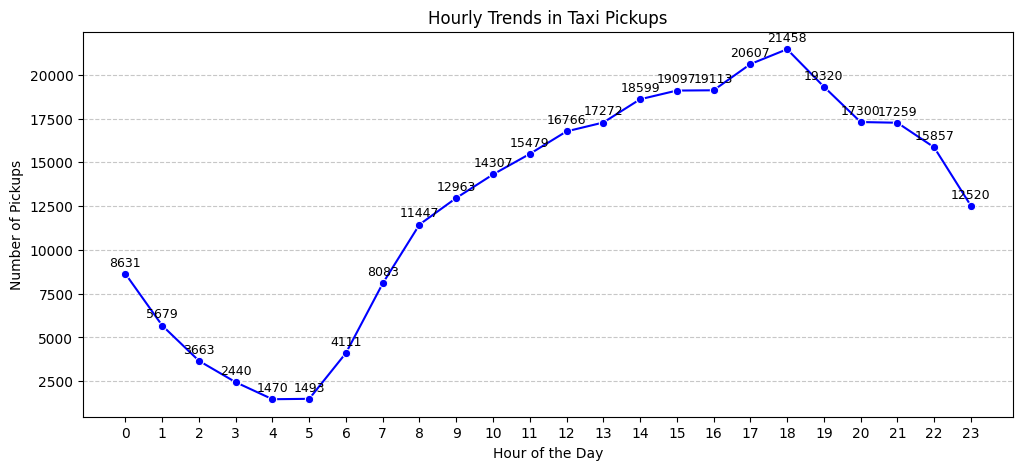

In [ ]:
# Hourly trends in pickups
hourly_pickups = df["tpep_pickup_datetime"].dt.hour.value_counts().sort_index()

hour_labels = [str(i) for i in range(24)]

plt.figure(figsize=(12, 5))
sns.lineplot(x=hour_labels[:len(hourly_pickups)], y=hourly_pickups.values, marker="o", color="blue")

y_min, y_max = plt.ylim()
offset = (y_max - y_min) * 0.02  # 2% of the range for spacing

for i, value in enumerate(hourly_pickups.values):
    plt.text(i, value + offset, str(value), ha="center", fontsize=9, color="black")

plt.xlabel("Hour of the Day")
plt.ylabel("Number of Pickups")
plt.title("Hourly Trends in Taxi Pickups")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

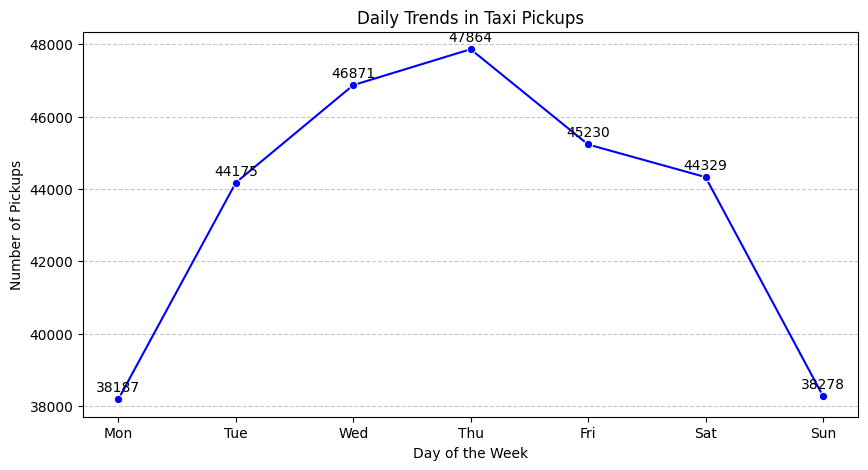

In [ ]:
# Daily trends in pickups (day of the week)
daily_pickups = df["tpep_pickup_datetime"].dt.dayofweek.value_counts().sort_index()

weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(10, 5))
sns.lineplot(x=weekday_labels, y=daily_pickups.values, marker="o", color="blue")

y_min, y_max = plt.ylim()
offset = (y_max - y_min) * 0.02

for i, value in enumerate(daily_pickups.values):
    plt.text(i, value + offset, str(value), ha="center", fontsize=10, color="black")

plt.xlabel("Day of the Week")
plt.ylabel("Number of Pickups")
plt.title("Daily Trends in Taxi Pickups")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

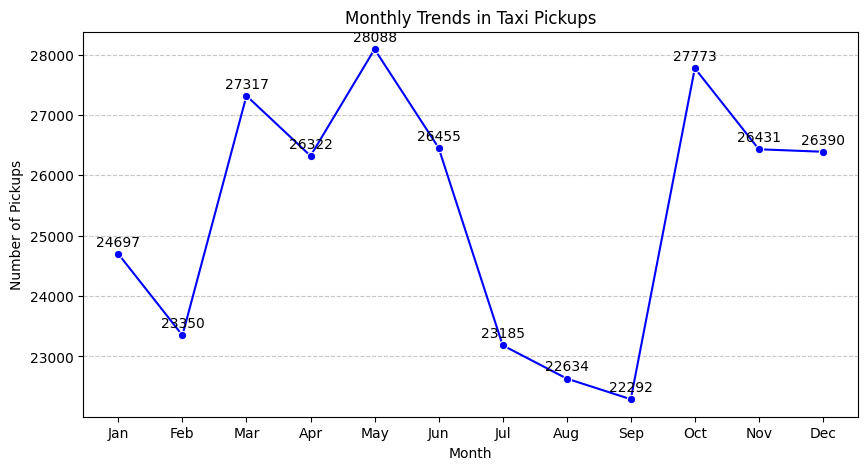

In [ ]:
# Monthly trends in pickups
monthly_pickups = df["tpep_pickup_datetime"].dt.month.value_counts().sort_index()

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 5))
sns.lineplot(x=month_labels[:len(monthly_pickups)], y=monthly_pickups.values, marker="o", color="blue")

y_min, y_max = plt.ylim()
offset = (y_max - y_min) * 0.02

for i, value in enumerate(monthly_pickups.values):
    plt.text(i, value + offset, str(value), ha="center", fontsize=10, color="black")

plt.xlabel("Month")
plt.ylabel("Number of Pickups")
plt.title("Monthly Trends in Taxi Pickups")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

#### Financial analysis

Do the fare, tip, total and distance columns still contain zero or negative values?

In [ ]:
financial_columns = ["fare_amount", "tip_amount", "total_amount", "trip_distance"]

negative_values = (df[financial_columns] < 0).sum()
print("Negative Value Counts:")
print(negative_values)

zero_values = (df[financial_columns] == 0).sum()
print("\nZero Value Counts:")
print(zero_values)

Negative Value Counts:
fare_amount      0
tip_amount       0
total_amount     0
trip_distance    0
dtype: int64

Zero Value Counts:
fare_amount        100
tip_amount       70563
total_amount        46
trip_distance     4101
dtype: int64


No negatives remain. Zero tips are common and legitimate (cash tips are not recorded), but a zero fare, total or distance usually means a value was not recorded. Trips with a zero in any of those three are excluded from the revenue and fare analyses below, in a separate frame, `df_filtered`.

In [ ]:
df_filtered = df[(df["trip_distance"] > 0) & (df["fare_amount"] > 0) & (df["total_amount"] > 0)].copy()

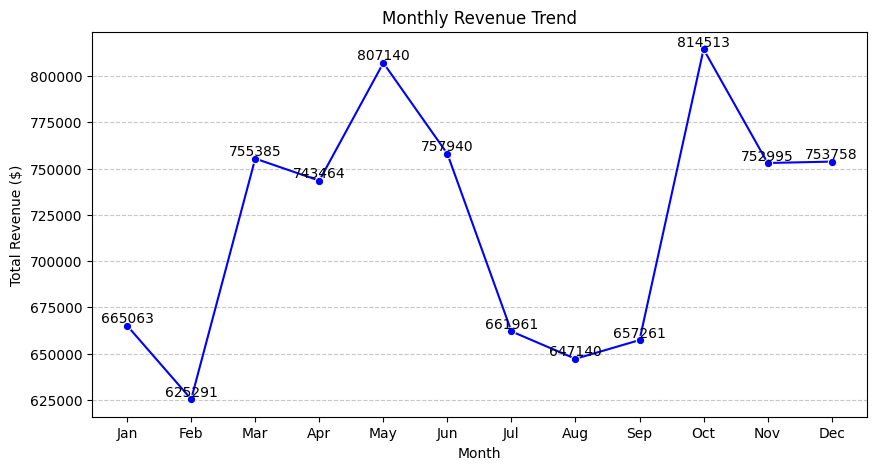

In [ ]:
# Monthly revenue
df_filtered["month"] = df_filtered["tpep_pickup_datetime"].dt.month

monthly_revenue = df_filtered.groupby("month")["total_amount"].sum().reset_index()

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_revenue["month"], y=monthly_revenue["total_amount"], marker="o", color="blue")

for i, value in enumerate(monthly_revenue["total_amount"]):
    plt.text(monthly_revenue["month"][i], value, f"{value:.0f}", ha="center", va="bottom", fontsize=10, color="black")

plt.xticks(ticks=monthly_revenue["month"], labels=month_labels[:len(monthly_revenue)])
plt.xlabel("Month")
plt.ylabel("Total Revenue ($)")
plt.title("Monthly Revenue Trend")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

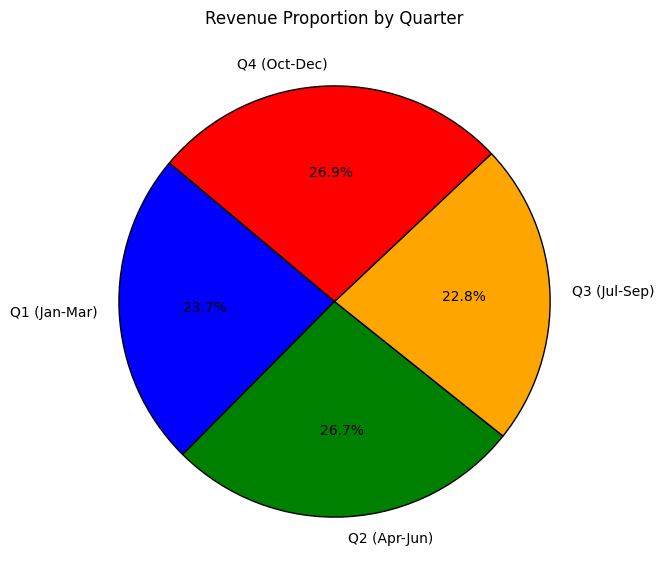

In [ ]:
# Share of annual revenue by quarter
df_filtered["quarter"] = df_filtered["tpep_pickup_datetime"].dt.quarter

quarterly_revenue = df_filtered.groupby("quarter")["total_amount"].sum()
quarterly_proportion = (quarterly_revenue / quarterly_revenue.sum()) * 100

quarter_labels = ["Q1 (Jan-Mar)", "Q2 (Apr-Jun)", "Q3 (Jul-Sep)", "Q4 (Oct-Dec)"]

plt.figure(figsize=(7, 7))
plt.pie(quarterly_proportion, labels=quarter_labels, autopct="%1.1f%%", colors=["blue", "green", "orange", "red"],
        startangle=140, wedgeprops={"edgecolor": "black"})
plt.title("Revenue Proportion by Quarter")
plt.show()

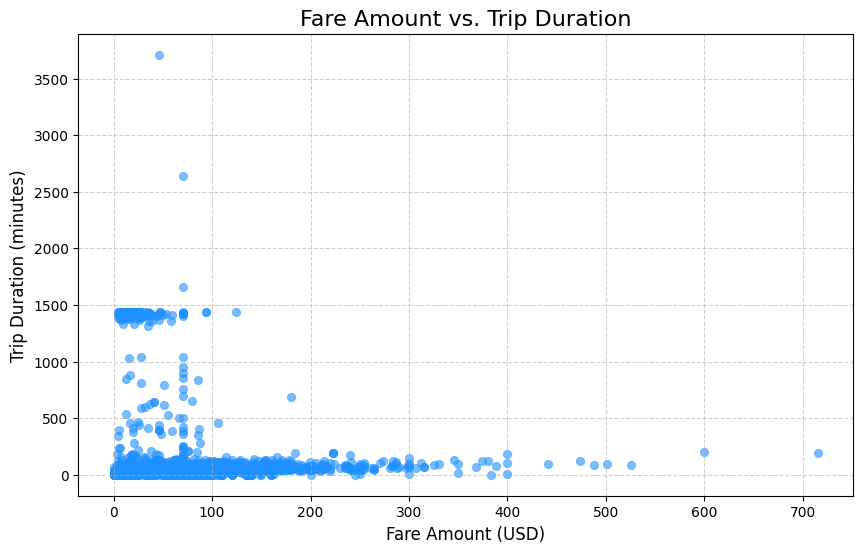

In [ ]:
# Trip duration in minutes, and how fare relates to it
df_filtered["trip_duration"] = (
    (df_filtered["tpep_dropoff_datetime"] - df_filtered["tpep_pickup_datetime"]).dt.total_seconds() / 60
)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_filtered, x="fare_amount", y="trip_duration", alpha=0.6, color="dodgerblue", edgecolor=None)
plt.title("Fare Amount vs. Trip Duration", fontsize=16)
plt.xlabel("Fare Amount (USD)", fontsize=12)
plt.ylabel("Trip Duration (minutes)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

The scatter plot shows a distinct band of trips lasting roughly 1,400 minutes (about 24 hours) and a few longer ones. These are almost certainly recording errors (a meter left running or a wrong drop-off timestamp). They are **not** removed in this analysis, which weakens the fare-versus-duration correlation and the route-speed analysis in 3.2.1; the limitation is also noted in the README.

Correlations between the main money and distance columns:

               trip_distance  fare_amount  total_amount  tip_amount  \
trip_distance       1.000000     0.942328      0.935285    0.591595   
fare_amount         0.942328     1.000000      0.980032    0.607221   
total_amount        0.935285     0.980032      1.000000    0.726428   
tip_amount          0.591595     0.607221      0.726428    1.000000   
tolls_amount        0.663299     0.648681      0.721096    0.493004   

               tolls_amount  
trip_distance      0.663299  
fare_amount        0.648681  
total_amount       0.721096  
tip_amount         0.493004  
tolls_amount       1.000000  


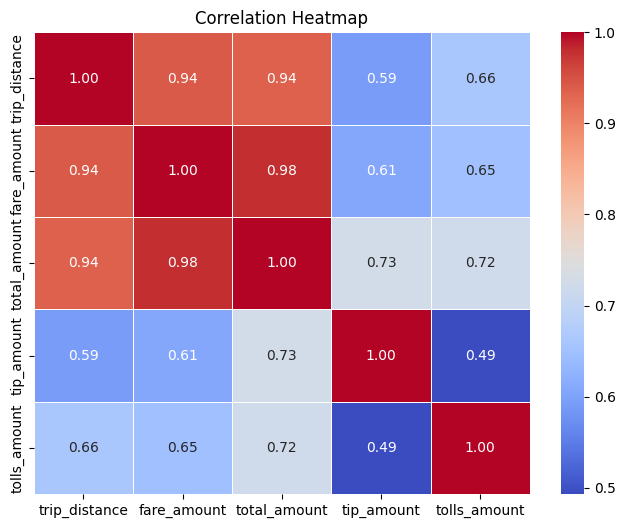

In [ ]:
corr_matrix = df_filtered[["trip_distance", "fare_amount", "total_amount", "tip_amount", "tolls_amount"]].corr()

print(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

Correlation Matrix:
               trip_duration  fare_amount  total_amount  trip_distance  \
trip_duration       1.000000     0.258614      0.251014       0.246233   
fare_amount         0.258614     1.000000      0.980032       0.942328   
total_amount        0.251014     0.980032      1.000000       0.935285   
trip_distance       0.246233     0.942328      0.935285       1.000000   
tip_amount          0.148946     0.607221      0.726428       0.591595   

               tip_amount  
trip_duration    0.148946  
fare_amount      0.607221  
total_amount     0.726428  
trip_distance    0.591595  
tip_amount       1.000000  


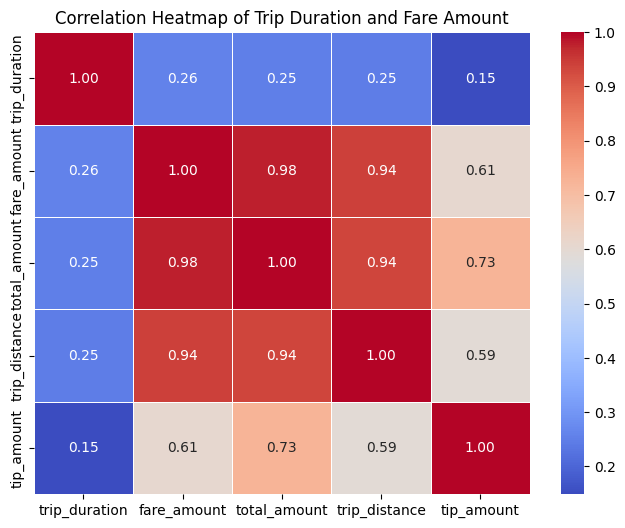

In [ ]:
# Fare vs trip duration (and related columns)
corr_columns = ["trip_duration", "fare_amount", "total_amount", "trip_distance", "tip_amount"]
corr_matrix = df_filtered[corr_columns].corr()

print("Correlation Matrix:")
print(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Trip Duration and Fare Amount")
plt.show()

Correlation Matrix:
                 fare_amount  passenger_count
fare_amount         1.000000         0.042246
passenger_count     0.042246         1.000000


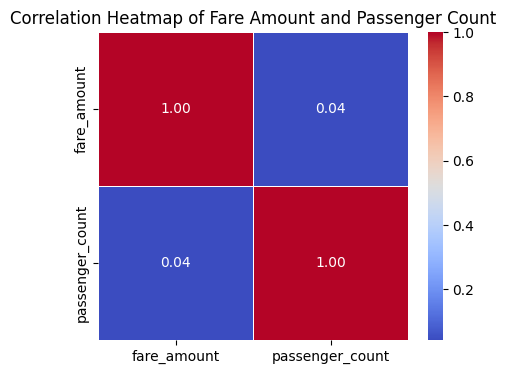

In [ ]:
# Fare vs number of passengers
corr_columns = ["fare_amount", "passenger_count"]
corr_matrix = df_filtered[corr_columns].corr()

print("Correlation Matrix:")
print(corr_matrix)

plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Fare Amount and Passenger Count")
plt.show()

Correlation Matrix:
               tip_amount  trip_distance
tip_amount       1.000000       0.591595
trip_distance    0.591595       1.000000


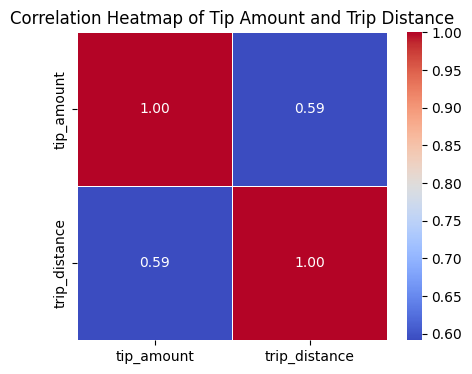

In [ ]:
# Tip vs trip distance
corr_columns = ["tip_amount", "trip_distance"]
corr_matrix = df_filtered[corr_columns].corr()

print("Correlation Matrix:")
print(corr_matrix)

plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Tip Amount and Trip Distance")
plt.show()

Fare tracks distance very closely (r ≈ 0.94), tips rise with distance more loosely (r ≈ 0.59), and the number of passengers barely affects the fare (r ≈ 0.04).

**Payment types** (codes from the TLC data dictionary: 1 credit card, 2 cash, 3 no charge, 4 dispute):

In [ ]:
payment_labels = {1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute"}

payment_counts = df_filtered["payment_type"].value_counts(normalize=True).sort_index() * 100
labels = payment_counts.index.map(payment_labels)

print("Payment Type Distribution (%):")
print(payment_counts.rename(index=payment_labels))

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=payment_counts.values, hue=labels, palette="viridis", legend=False)
plt.xlabel("Payment Type")
plt.ylabel("Percentage of Transactions")
plt.title("Distribution of Payment Types")

for i, v in enumerate(payment_counts.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=10)
plt.show()

#### Geographical analysis

Each trip records pickup and drop-off as a TLC taxi-zone ID (1 to 263). The TLC shapefile maps those IDs to zone names, boroughs and polygons, which lets trips be joined to zones and drawn on a map. `data/README.md` shows the folder layout (`taxi_zones/taxi_zones.shp` plus its companion files, which must stay together).

In [ ]:
# !pip install geopandas
import geopandas as gpd

print(gpd.__version__)

1.0.1


In [ ]:
zones = gpd.read_file(ZONES_SHP)
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    object  
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    object  
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), object(2)
memory usage: 12.5+ KB
None


<Axes: >

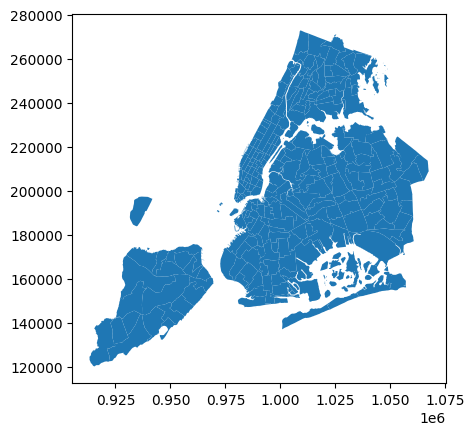

In [ ]:
print(zones.info())
zones.plot()

In [ ]:
# Attach zone details to each trip via its pickup zone
merged_data = df_filtered.merge(zones, how="left", left_on="PULocationID", right_on="LocationID")

merged_data.drop(columns=["LocationID"], inplace=True)

merged_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300792 entries, 0 to 300791
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               300792 non-null  int64         
 1   tpep_pickup_datetime   300792 non-null  datetime64[us]
 2   tpep_dropoff_datetime  300792 non-null  datetime64[us]
 3   passenger_count        300792 non-null  float64       
 4   trip_distance          300792 non-null  float64       
 5   RatecodeID             300792 non-null  float64       
 6   PULocationID           300792 non-null  int64         
 7   DOLocationID           300792 non-null  int64         
 8   payment_type           300792 non-null  int64         
 9   fare_amount            300792 non-null  float64       
 10  extra                  300792 non-null  float64       
 11  mta_tax                300792 non-null  float64       
 12  tip_amount             300792 non-null  floa

In [ ]:
# Total trips per pickup zone
trips_per_location = merged_data.groupby("PULocationID").size().reset_index(name="total_trips")

trips_per_location.head()

,PULocationID,total_trips
0,1,13
1,3,4
2,4,295
3,5,5
4,6,5


In [ ]:
# Add the trip counts back onto the zone polygons so they can be mapped
zones_with_trips = zones.merge(trips_per_location, how="left", left_on="LocationID", right_on="PULocationID")

zones_with_trips["total_trips"] = zones_with_trips["total_trips"].fillna(0)
zones_with_trips.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,PULocationID,total_trips
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19...",1.0,13.0
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343...",NaN,0.0
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2...",3.0,4.0
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20...",4.0,295.0
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144...",5.0,5.0


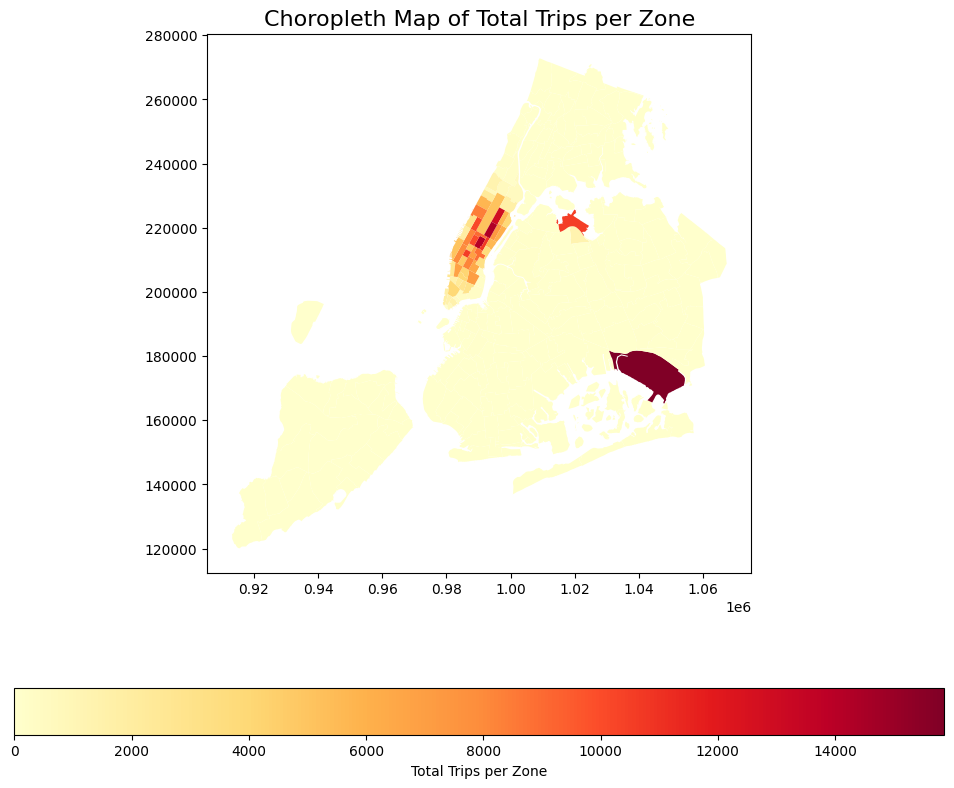

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

zones_with_trips.plot(
    column="total_trips",
    ax=ax,
    legend=True,
    legend_kwds={"label": "Total Trips per Zone", "orientation": "horizontal"},
    cmap="YlOrRd",
)

ax.set_title("Choropleth Map of Total Trips per Zone", fontsize=16)
plt.show()

In [ ]:
# Zones ranked by number of pickups
zones_with_trips.sort_values(by="total_trips", ascending=False).reset_index(drop=True)

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,PULocationID,total_trips
0,132,0.245479,0.002038,JFK Airport,132,Queens,"MULTIPOLYGON (((1032791.001 181085.006, 103283...",132.0,15864.0
1,237,0.042213,0.000096,Upper East Side South,237,Manhattan,"POLYGON ((993633.442 216961.016, 993507.232 21...",237.0,14296.0
2,161,0.035804,0.000072,Midtown Center,161,Manhattan,"POLYGON ((991081.026 214453.698, 990952.644 21...",161.0,14099.0
3,236,0.044252,0.000103,Upper East Side North,236,Manhattan,"POLYGON ((995940.048 221122.92, 995812.322 220...",236.0,12860.0
4,162,0.035270,0.000048,Midtown East,162,Manhattan,"POLYGON ((992224.354 214415.293, 992096.999 21...",162.0,10749.0
...,...,...,...,...,...,...,...,...,...
258,84,0.233624,0.002074,Eltingville/Annadale/Prince's Bay,84,Staten Island,"POLYGON ((939754.454 131548.91, 939802.804 131...",NaN,0.0
259,99,0.183371,0.001210,Freshkills Park,99,Staten Island,"POLYGON ((937468.341 152998.406, 937320.263 15...",NaN,0.0
260,30,0.094510,0.000146,Broad Channel,30,Queens,"POLYGON ((1034013.272 163473.152, 1034866.459 ...",NaN,0.0
261,245,0.095983,0.000466,West Brighton,245,Staten Island,"POLYGON ((957085.564 172591.26, 957142.385 172...",NaN,0.0


#### What the general analysis shows

- **Busiest hours:** pickups bottom out around 4–5 am and peak at 6 pm (hour 18).
- **Busiest months:** May and October lead; July to September, and February, are the quietest.
- **Revenue:** follows the same seasonal shape; Q2 and Q4 together bring in about 54% of the year's revenue (26.7% and 26.9%), with Q3 the weakest (22.8%).
- **Fares:** driven by distance, not by passenger count; tips rise with distance but only loosely.
- **Payment:** credit card is about 81% of trips and cash about 17%.
- **Busiest zones:** JFK Airport, the Upper East Side and Midtown top the pickup ranking.

### 3.2 Detailed EDA: operations, pricing and customer experience

#### Operational efficiency

**Route speed.** For each pickup-zone → drop-off-zone route and hour of day, speed is total distance divided by total time. `trip_duration` is in minutes, so it is divided by 60 to give miles per hour.

*Caveat:* the duration outliers described above (the ~24-hour band) are still in the data, so the slowest routes this produces are dominated by implausible trips and should be read as a method demonstration, not a finding. Duration cleaning is not part of this analysis (see the limitations in the README).

In [ ]:
# Slowest route in each hour of the day
avg_speeds = merged_data.groupby(
    [merged_data["PULocationID"], merged_data["DOLocationID"], merged_data["tpep_pickup_datetime"].dt.hour]
).agg(
    avg_speed=("trip_distance", lambda x: x.sum() / (merged_data.loc[x.index, "trip_duration"].sum() / 60)),
    avg_duration=("trip_duration", "mean"),
    total_distance=("trip_distance", "sum"),
    trip_count=("trip_distance", "count"),
).reset_index()

avg_speeds.rename(columns={"tpep_pickup_datetime": "hour"}, inplace=True)

slowest_routes = avg_speeds.loc[avg_speeds.groupby("hour")["avg_speed"].idxmin()]
slowest_routes.head().reset_index(drop=True)

**Trips per hour.** Number of sampled trips in each hour, with the busiest hour marked.

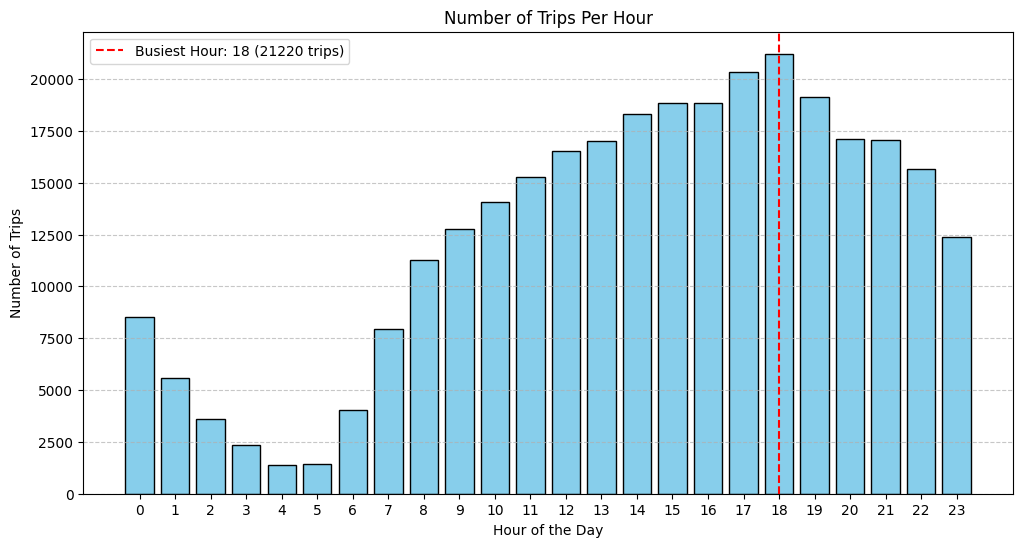

Busiest hour: 18 with 21220 trips.


In [ ]:
trips_per_hour = (
    merged_data.groupby(merged_data["tpep_pickup_datetime"].dt.hour)
    .size()
    .reset_index(name="num_trips")
)

trips_per_hour.rename(columns={"tpep_pickup_datetime": "hour"}, inplace=True)

busiest_hour = trips_per_hour.loc[trips_per_hour["num_trips"].idxmax()]

plt.figure(figsize=(12, 6))
plt.bar(trips_per_hour["hour"], trips_per_hour["num_trips"], color="skyblue", edgecolor="black")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Trips")
plt.title("Number of Trips Per Hour")
plt.xticks(range(0, 24))
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.axvline(busiest_hour["hour"], color="red", linestyle="--",
            label=f"Busiest Hour: {busiest_hour['hour']} ({busiest_hour['num_trips']} trips)")
plt.legend()
plt.show()
print(f"Busiest hour: {busiest_hour['hour']} with {busiest_hour['num_trips']} trips.")

**Scaling back up.** Only 0.75% of trips were kept, so dividing the sampled counts by `SAMPLE_FRACTION` estimates the real number of trips. (These are estimates: the cleaning steps also removed some sampled rows.)

Top 5 busiest hours:
    hour  num_trips  actual_num_trips
18    18      21220      2.829333e+06
17    17      20354      2.713867e+06
19    19      19135      2.551333e+06
16    16      18857      2.514267e+06
15    15      18820      2.509333e+06


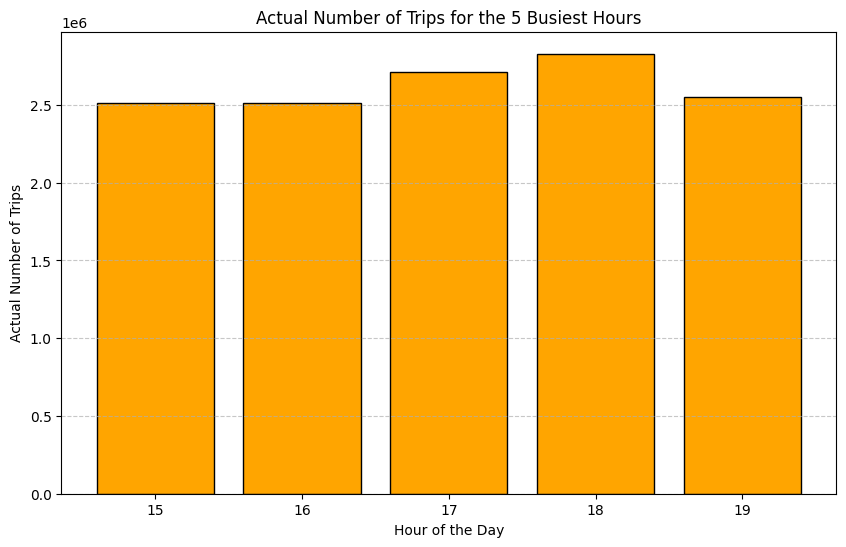

In [ ]:
trips_per_hour["actual_num_trips"] = trips_per_hour["num_trips"] / SAMPLE_FRACTION

top_5_busiest_hours = trips_per_hour.nlargest(5, "actual_num_trips")

print("Top 5 busiest hours:")
print(top_5_busiest_hours)

plt.figure(figsize=(10, 6))
plt.bar(top_5_busiest_hours["hour"], top_5_busiest_hours["actual_num_trips"], color="orange", edgecolor="black")
plt.xlabel("Hour of the Day")
plt.ylabel("Actual Number of Trips")
plt.title("Actual Number of Trips for the 5 Busiest Hours")
plt.xticks(top_5_busiest_hours["hour"])
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

**Weekdays versus weekends.** Estimated trips per hour, summed over all weekdays and over all weekend days.

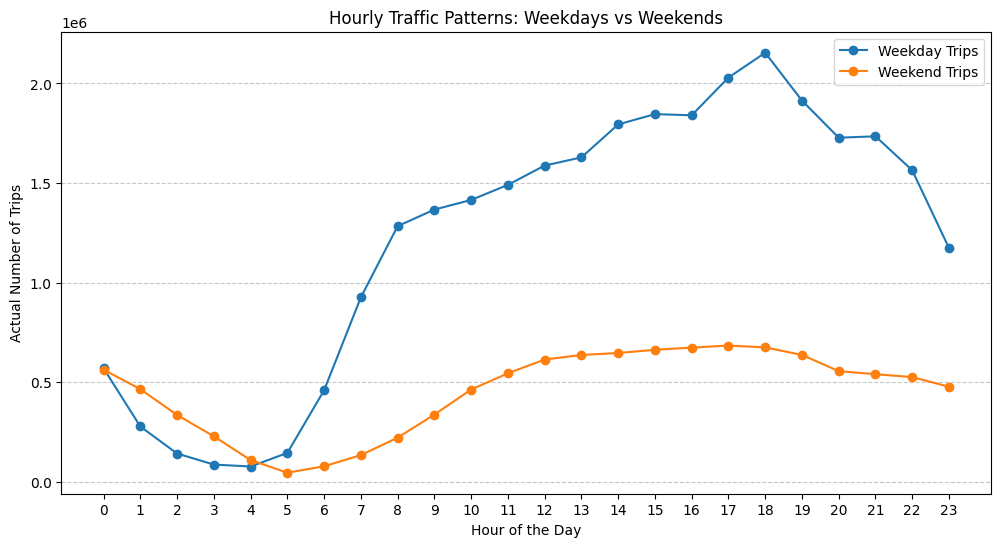

In [ ]:
merged_data["day_of_week"] = merged_data["tpep_pickup_datetime"].dt.dayofweek
merged_data["hour"] = merged_data["tpep_pickup_datetime"].dt.hour

weekday_data = merged_data[merged_data["day_of_week"] < 5]    # Monday to Friday
weekend_data = merged_data[merged_data["day_of_week"] >= 5]   # Saturday and Sunday
weekday_trips = weekday_data.groupby("hour").size() / SAMPLE_FRACTION
weekend_trips = weekend_data.groupby("hour").size() / SAMPLE_FRACTION

hourly_comparison = pd.DataFrame({
    "Weekday Trips": weekday_trips,
    "Weekend Trips": weekend_trips,
}).reset_index().rename(columns={"hour": "Hour"})

plt.figure(figsize=(12, 6))
plt.plot(hourly_comparison["Hour"], hourly_comparison["Weekday Trips"], label="Weekday Trips", marker="o")
plt.plot(hourly_comparison["Hour"], hourly_comparison["Weekend Trips"], label="Weekend Trips", marker="o")
plt.xlabel("Hour of the Day")
plt.ylabel("Actual Number of Trips")
plt.title("Hourly Traffic Patterns: Weekdays vs Weekends")
plt.xticks(range(0, 24))
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.show()

In [ ]:
hourly_comparison.head()

,Hour,Weekday Trips,Weekend Trips
0,0,570400.000000,563333.333333
1,1,278400.000000,465600.000000
2,2,142666.666667,336000.000000
3,3,87200.000000,228800.000000
4,4,77466.666667,110000.000000


- **Weekdays:** trips climb from about 6 am, reach a shoulder at 8–9 am, keep rising through the afternoon and peak at 6 pm, then fall away towards midnight. That is a commuting pattern, with the evening the busiest period.
- **Weekends:** the profile is much flatter, a gentle rise to a peak around 5 pm, which points to leisure travel rather than commuting.
- **Late night:** from about 1 am to 4 am, weekends are *busier* than weekdays, even though they cover only two days of the week.
- Weekday totals are higher partly because there are five weekdays to two weekend days; the comparison above is not per day.

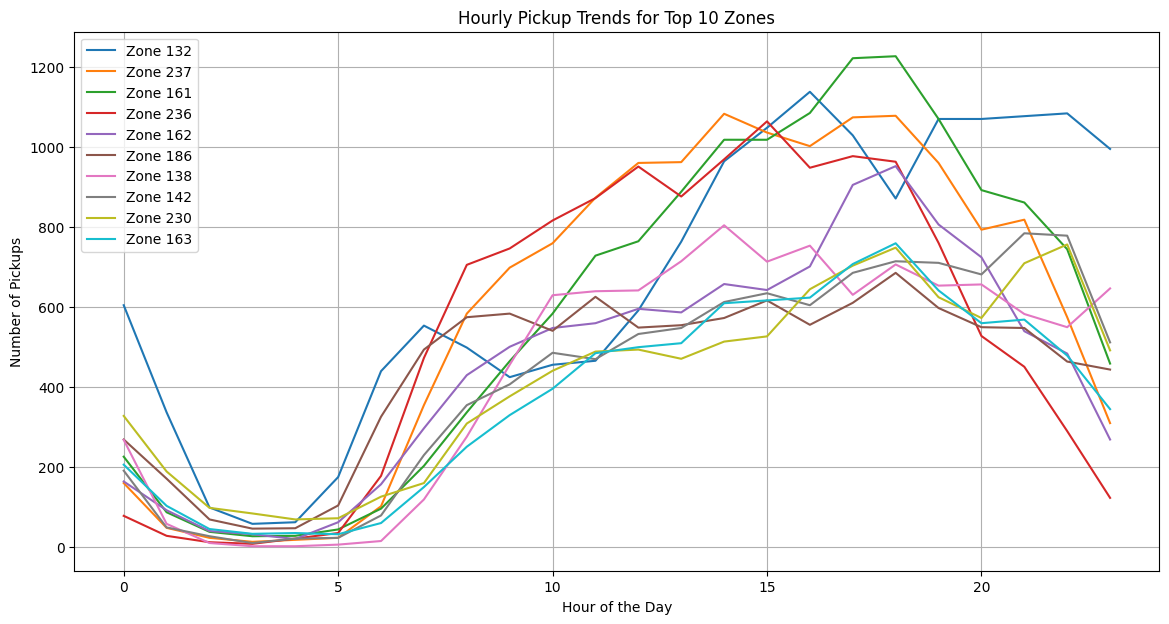

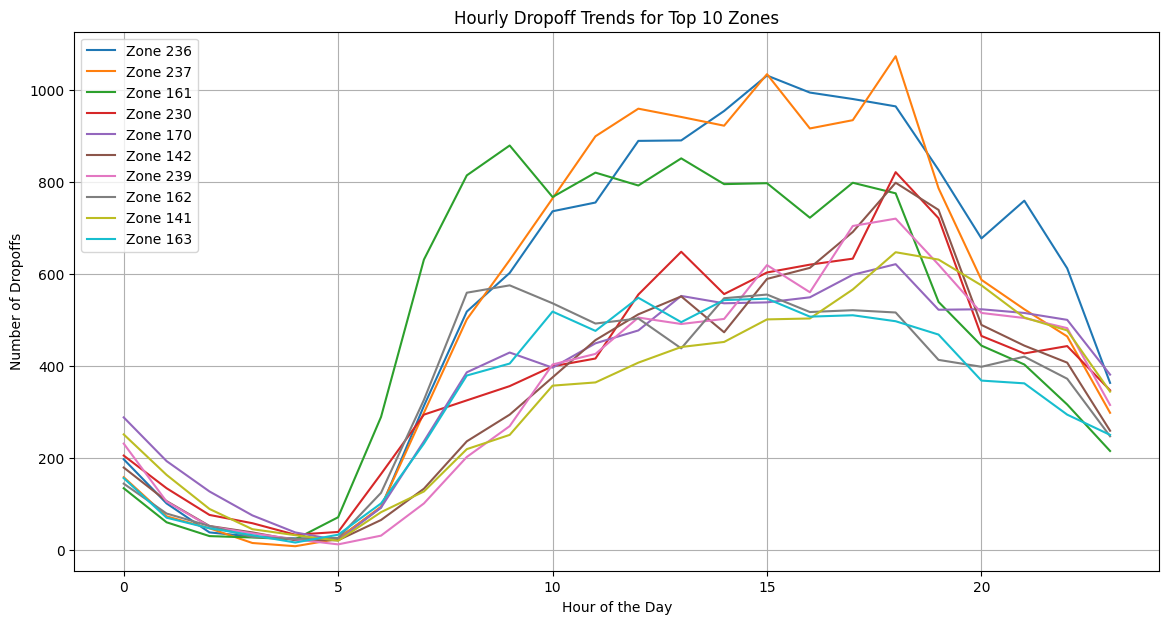

In [ ]:
# Top 10 pickup and drop-off zones and their hourly trends
merged_data["tpep_pickup_datetime"] = pd.to_datetime(merged_data["tpep_pickup_datetime"], errors="coerce")
merged_data["tpep_dropoff_datetime"] = pd.to_datetime(merged_data["tpep_dropoff_datetime"], errors="coerce")
merged_data = merged_data.dropna(subset=["tpep_pickup_datetime", "tpep_dropoff_datetime"])

hourly_pickups = (
    merged_data.groupby(["PULocationID", merged_data["tpep_pickup_datetime"].dt.hour])
    .size()
    .reset_index(name="total_pickups")
)

hourly_dropoffs = (
    merged_data.groupby(["DOLocationID", merged_data["tpep_dropoff_datetime"].dt.hour])
    .size()
    .reset_index(name="total_dropoffs")
)

top_pickup_zones = hourly_pickups.groupby("PULocationID")["total_pickups"].sum().nlargest(10).index
top_dropoff_zones = hourly_dropoffs.groupby("DOLocationID")["total_dropoffs"].sum().nlargest(10).index

top_pickup_trends = hourly_pickups[hourly_pickups["PULocationID"].isin(top_pickup_zones)]
top_dropoff_trends = hourly_dropoffs[hourly_dropoffs["DOLocationID"].isin(top_dropoff_zones)]

plt.figure(figsize=(14, 7))
for zone in top_pickup_zones:
    zone_data = top_pickup_trends[top_pickup_trends["PULocationID"] == zone]
    plt.plot(zone_data.iloc[:, 1], zone_data["total_pickups"], label=f"Zone {zone}")  # column 1 is the hour
plt.title("Hourly Pickup Trends for Top 10 Zones")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Pickups")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(14, 7))
for zone in top_dropoff_zones:
    zone_data = top_dropoff_trends[top_dropoff_trends["DOLocationID"] == zone]
    plt.plot(zone_data.iloc[:, 1], zone_data["total_dropoffs"], label=f"Zone {zone}")
plt.title("Hourly Dropoff Trends for Top 10 Zones")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Dropoffs")
plt.legend()
plt.grid()
plt.show()

**Pickup-to-drop-off ratio per zone.** A high ratio means cabs pick up there but rarely end trips there, so they leave empty and supply has to be brought in; a low ratio means the opposite.

In [ ]:
pickup_counts = merged_data.groupby("PULocationID").size().reset_index(name="total_pickups")
dropoff_counts = merged_data.groupby("DOLocationID").size().reset_index(name="total_dropoffs")

pickup_dropoff_ratios = pickup_counts.merge(
    dropoff_counts, left_on="PULocationID", right_on="DOLocationID", how="outer"
).fillna(0)

pickup_dropoff_ratios.rename(
    columns={"PULocationID": "LocationID", "total_pickups": "pickups", "total_dropoffs": "dropoffs"},
    inplace=True,
)

# Zones with no drop-offs would divide by zero, so treat their drop-offs as 1
pickup_dropoff_ratios["pickup_dropoff_ratio"] = (
    pickup_dropoff_ratios["pickups"] / pickup_dropoff_ratios["dropoffs"].replace(0, 1)
)

top_10_ratios = pickup_dropoff_ratios.sort_values(by="pickup_dropoff_ratio", ascending=False).head(10)
bottom_10_ratios = pickup_dropoff_ratios.sort_values(by="pickup_dropoff_ratio", ascending=True).head(10)

print("Top 10 Pickup/Dropoff Ratios:\n")
print(top_10_ratios.reset_index(drop=True))
print("\nBottom 10 Pickup/Dropoff Ratios:\n")
print(bottom_10_ratios.reset_index(drop=True))

Top 10 Pickup/Dropoff Ratios:

   LocationID  pickups  DOLocationID  dropoffs  pickup_dropoff_ratio
0        70.0   1359.0            70       186              7.306452
1       132.0  15864.0           132      3211              4.940517
2       138.0  10517.0           138      3622              2.903644
3       186.0  10579.0           186      6731              1.571683
4        43.0   5112.0            43      3674              1.391399
5       249.0   6805.0           249      4995              1.362362
6       114.0   3983.0           114      2967              1.342433
7       162.0  10749.0           162      8412              1.277817
8       142.0  10128.0           142      8541              1.185810
9       100.0   4952.0           100      4211              1.175968

Bottom 10 Pickup/Dropoff Ratios:

   LocationID  pickups  DOLocationID  dropoffs  pickup_dropoff_ratio
0         0.0      0.0           245         3                   0.0
1         0.0      0.0           221 

**Night-time demand (11 pm to 5 am).** The zones that matter overnight are ranked on night-time trips only, not on overall volume.

In [ ]:
night_data = merged_data[(merged_data["hour"] >= 23) | (merged_data["hour"] <= 5)]

night_pickups = (
    night_data.groupby("PULocationID").size()
    .reset_index(name="pickup_count")
    .sort_values(by="pickup_count", ascending=False)
)

night_dropoffs = (
    night_data.groupby("DOLocationID").size()
    .reset_index(name="dropoff_count")
    .sort_values(by="dropoff_count", ascending=False)
)

top_night_pickups = night_pickups.head(10).reset_index(drop=True)
top_night_dropoffs = night_dropoffs.head(10).reset_index(drop=True)

print("Top 10 Pickup Zones during Night Hours:\n")
print(top_night_pickups)
print("\nTop 10 Dropoff Zones during Night Hours:\n")
print(top_night_dropoffs)

Top 10 Pickup Zones during Night Hours:

   PULocationID  pickup_count
0            79          2529
1           132          2325
2           249          2033
3            48          1712
4           148          1536
5           114          1421
6           230          1325
7           186          1143
8            68          1001
9           138           986

Top 10 Dropoff Zones during Night Hours:

   DOLocationID  dropoff_count
0            79           1365
1            48           1130
2           170           1057
3           107            959
4            68            928
5           141            870
6           263            847
7           249            784
8           230            782
9           229            752


**Revenue share, night versus day.**

In [ ]:
night_data = merged_data[(merged_data["hour"] >= 23) | (merged_data["hour"] <= 5)]
day_data = merged_data[(merged_data["hour"] >= 6) & (merged_data["hour"] <= 22)]
night_revenue = night_data["total_amount"].sum()
day_revenue = day_data["total_amount"].sum()

total_revenue = merged_data["total_amount"].sum()

night_revenue_share = (night_revenue / total_revenue) * 100
day_revenue_share = (day_revenue / total_revenue) * 100

print(f"Nighttime Revenue Share: {night_revenue_share:.2f}%")
print(f"Daytime Revenue Share: {day_revenue_share:.2f}%")

Nighttime Revenue Share: 11.86%
Daytime Revenue Share: 88.14%


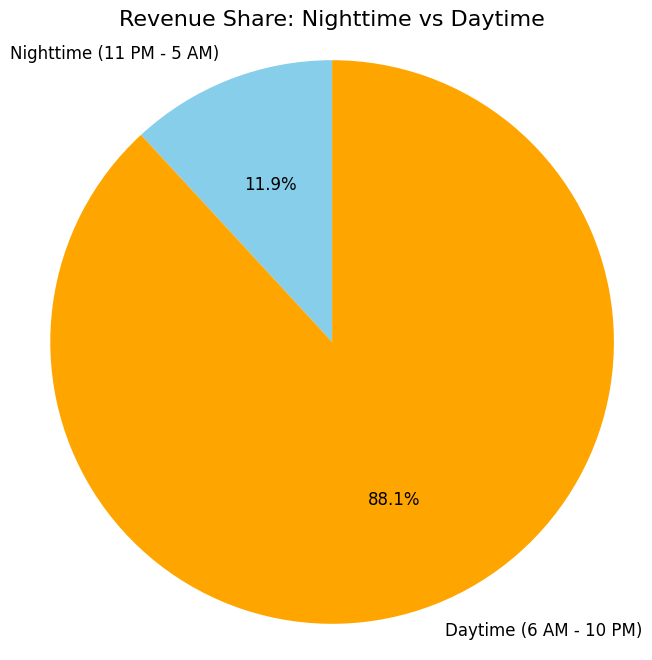

In [ ]:
labels = ["Nighttime (11 PM - 5 AM)", "Daytime (6 AM - 10 PM)"]
sizes = [night_revenue_share, day_revenue_share]
colors = ["skyblue", "orange"]

plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=90, colors=colors, textprops={"fontsize": 12})
plt.title("Revenue Share: Nighttime vs Daytime", fontsize=16)
plt.axis("equal")
plt.show()

The seven night hours (11 pm to 5 am) bring in about 12% of revenue.

#### Pricing strategy

**Fare per mile per passenger** by group size. *Caveat:* these are averages of per-trip ratios, so very short trips (tiny distances) inflate them; a median would be more robust.

In [ ]:
merged_data["fare_per_mile"] = merged_data["fare_amount"] / merged_data["trip_distance"]
merged_data["fare_per_mile_per_passenger"] = merged_data["fare_per_mile"] / merged_data["passenger_count"]

fare_analysis = (
    merged_data.groupby("passenger_count")["fare_per_mile_per_passenger"]
    .mean()
    .reset_index(name="avg_fare_per_mile_per_passenger")
)
fare_analysis

,passenger_count,avg_fare_per_mile_per_passenger
0,1.0,11.773553
1,2.0,7.651142
2,3.0,4.668805
3,4.0,6.859530
4,5.0,1.769213
5,6.0,1.468884


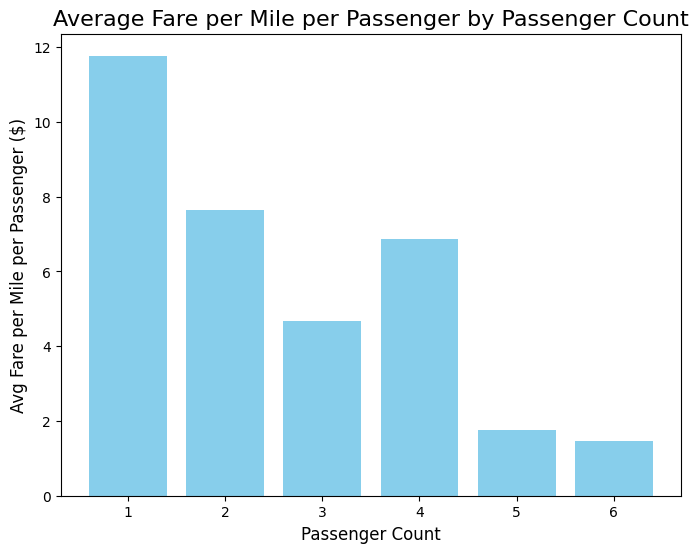

In [ ]:
plt.figure(figsize=(8, 6))
plt.bar(fare_analysis["passenger_count"], fare_analysis["avg_fare_per_mile_per_passenger"], color="skyblue")
plt.xlabel("Passenger Count", fontsize=12)
plt.ylabel("Avg Fare per Mile per Passenger ($)", fontsize=12)
plt.title("Average Fare per Mile per Passenger by Passenger Count", fontsize=16)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

**Fare per mile by hour and by day of the week.**

In [ ]:
merged_data["fare_per_mile"] = merged_data["fare_amount"] / merged_data["trip_distance"]
hourly_fare = (
    merged_data.groupby(merged_data["tpep_pickup_datetime"].dt.hour)["fare_per_mile"]
    .mean()
    .reset_index(name="avg_fare_per_mile")
)
daily_fare = (
    merged_data.groupby(merged_data["tpep_pickup_datetime"].dt.dayofweek)["fare_per_mile"]
    .mean()
    .reset_index(name="avg_fare_per_mile")
)

day_map = {0: "Monday", 1: "Tuesday", 2: "Wednesday", 3: "Thursday", 4: "Friday", 5: "Saturday", 6: "Sunday"}
daily_fare["day_of_week"] = daily_fare["tpep_pickup_datetime"].map(day_map)

print("Hourly Fare:")
hourly_fare

Hourly Fare:


,tpep_pickup_datetime,avg_fare_per_mile
0,0,14.199902
1,1,20.376621
2,2,13.998736
3,3,9.588733
4,4,20.546811
5,5,13.681752
6,6,12.484506
7,7,11.598620
8,8,10.273847
9,9,10.223936


In [ ]:
print("\nDaily Fare:")
daily_fare


Daily Fare:


,tpep_pickup_datetime,avg_fare_per_mile,day_of_week
0,0,11.750786,Monday
1,1,11.154275,Tuesday
2,2,11.696271,Wednesday
3,3,12.561642,Thursday
4,4,13.432997,Friday
5,5,13.113942,Saturday
6,6,15.235471,Sunday


**Fare per mile by vendor and hour.**

In [ ]:
merged_data = merged_data[merged_data["trip_distance"] > 0]
vendor_hourly_fare = (
    merged_data.groupby(["VendorID", merged_data["tpep_pickup_datetime"].dt.hour])["fare_per_mile"]
    .mean()
    .reset_index(name="avg_fare_per_mile")
)

vendor_hourly_fare.rename(columns={"tpep_pickup_datetime": "hour"}, inplace=True)
vendor_hourly_fare.head(30)

,VendorID,hour,avg_fare_per_mile
0,1,0,6.976399
1,1,1,6.911234
2,1,2,6.931983
3,1,3,6.537589
4,1,4,6.497069
5,1,5,8.142258
6,1,6,6.381794
7,1,7,7.303040
8,1,8,8.164804
9,1,9,9.154144


**Tiered fares by distance** (up to 2 miles, 2 to 5 miles, over 5 miles), compared across vendors.

In [ ]:
def distance_tier(distance):
    if distance <= 2:
        return "0-2 miles"
    elif 2 < distance <= 5:
        return "2-5 miles"
    else:
        return "5+ miles"

merged_data["distance_tier"] = merged_data["trip_distance"].apply(distance_tier)
tiered_fare_analysis = (
    merged_data.groupby(["VendorID", "distance_tier"])["fare_per_mile"]
    .mean()
    .reset_index(name="avg_fare_per_mile")
)
print(tiered_fare_analysis)

   VendorID distance_tier  avg_fare_per_mile
0         1     0-2 miles          10.019046
1         1     2-5 miles           6.390762
2         1      5+ miles           4.434776
3         2     0-2 miles          21.171988
4         2     2-5 miles           6.551253
5         2      5+ miles           4.505971


Short trips earn far more *per mile* than long ones (the starting charge and very short distances inflate the ratio), and the two vendors differ sharply only on trips under two miles.

#### Customer experience and other factors

**Tip percentage** (tip as a share of the fare) by trip distance, passenger count and pickup time.

In [ ]:
merged_data["tip_percentage"] = (merged_data["tip_amount"] / merged_data["fare_amount"]) * 100
merged_data = merged_data[merged_data["fare_amount"] > 0]
merged_data["distance_tier"] = merged_data["trip_distance"].apply(distance_tier)

tip_by_distance = (
    merged_data.groupby("distance_tier")["tip_percentage"]
    .mean()
    .reset_index(name="avg_tip_percentage")
)
tip_by_distance

,distance_tier,avg_tip_percentage
0,0-2 miles,22.178434
1,2-5 miles,18.595450
2,5+ miles,20.300446


In [ ]:
tip_by_passenger = (
    merged_data.groupby("passenger_count")["tip_percentage"]
    .mean()
    .reset_index(name="avg_tip_percentage")
)

tip_by_passenger

,passenger_count,avg_tip_percentage
0,1.0,20.497671
1,2.0,19.548681
2,3.0,18.747397
3,4.0,17.468087
4,5.0,71.757290
5,6.0,20.524519


Average tip is about 18–22% across distance bands, lowest for 2–5 mile trips. The 5-passenger figure (about 72%) is an outlier, since the other groups sit at 17–21%; it is likely driven by a few trips with large tips relative to very small fares, and a median or a cap would be more robust.

**Passenger count by hour, day of week and zone.**

In [ ]:
passenger_by_hour = (
    merged_data.groupby(merged_data["tpep_pickup_datetime"].dt.hour)["passenger_count"]
    .mean()
    .reset_index(name="avg_passenger_count")
)

print(passenger_by_hour)

    tpep_pickup_datetime  avg_passenger_count
0                      0             1.405857
1                      1             1.450538
2                      2             1.453760
3                      3             1.462447
4                      4             1.372688
5                      5             1.281445
6                      6             1.233474
7                      7             1.293253
8                      8             1.300894
9                      9             1.310056
10                    10             1.348921
11                    11             1.371096
12                    12             1.371012
13                    13             1.396823
14                    14             1.402785
15                    15             1.419766
16                    16             1.405049
17                    17             1.394959
18                    18             1.391800
19                    19             1.397753
20                    20          

In [ ]:
merged_data["tpep_pickup_datetime"] = pd.to_datetime(merged_data["tpep_pickup_datetime"])
merged_data["day_of_week"] = merged_data["tpep_pickup_datetime"].dt.dayofweek

passenger_by_day = (
    merged_data.groupby("day_of_week")["passenger_count"]
    .mean()
    .reset_index(name="avg_passenger_count")
)

days_map = {0: "Monday", 1: "Tuesday", 2: "Wednesday", 3: "Thursday", 4: "Friday", 5: "Saturday", 6: "Sunday"}
passenger_by_day["day"] = passenger_by_day["day_of_week"].map(days_map)
print(passenger_by_day)

   day_of_week  avg_passenger_count        day
0            0             1.360143     Monday
1            1             1.341831    Tuesday
2            2             1.333204  Wednesday
3            3             1.346928   Thursday
4            4             1.402567     Friday
5            5             1.479148   Saturday
6            6             1.463798     Sunday


In [ ]:
passenger_by_zone = (
    merged_data.groupby("PULocationID")["passenger_count"]
    .mean()
    .reset_index(name="avg_passenger_count")
    .sort_values(by="avg_passenger_count", ascending=False)
)

zones_with_passenger_counts = zones.merge(
    passenger_by_zone, how="left", left_on="LocationID", right_on="PULocationID"
)

zones_with_passenger_counts["avg_passenger_count"] = zones_with_passenger_counts["avg_passenger_count"].fillna(0)

print(zones_with_passenger_counts.sort_values("avg_passenger_count", ascending=False).head())

     OBJECTID  Shape_Leng  Shape_Area                       zone  LocationID  \
5           6    0.150491    0.000606    Arrochar/Fort Wadsworth           6   
170       171    0.107354    0.000520         Murray Hill-Queens         171   
168       169    0.060105    0.000146                 Mount Hope         169   
218       219    0.155127    0.000428  Springfield Gardens South         219   
0           1    0.116357    0.000782             Newark Airport           1   

           borough                                           geometry  \
5    Staten Island  POLYGON ((966568.747 158679.855, 966615.256 15...   
170         Queens  POLYGON ((1041536.76 220023.061, 1041527.85 21...   
168          Bronx  POLYGON ((1012420.96 250846.784, 1012291.557 2...   
218         Queens  POLYGON ((1050324.836 182327.776, 1050609.77 1...   
0              EWR  POLYGON ((933100.918 192536.086, 933091.011 19...   

     PULocationID  avg_passenger_count  
5             6.0             2.600000 

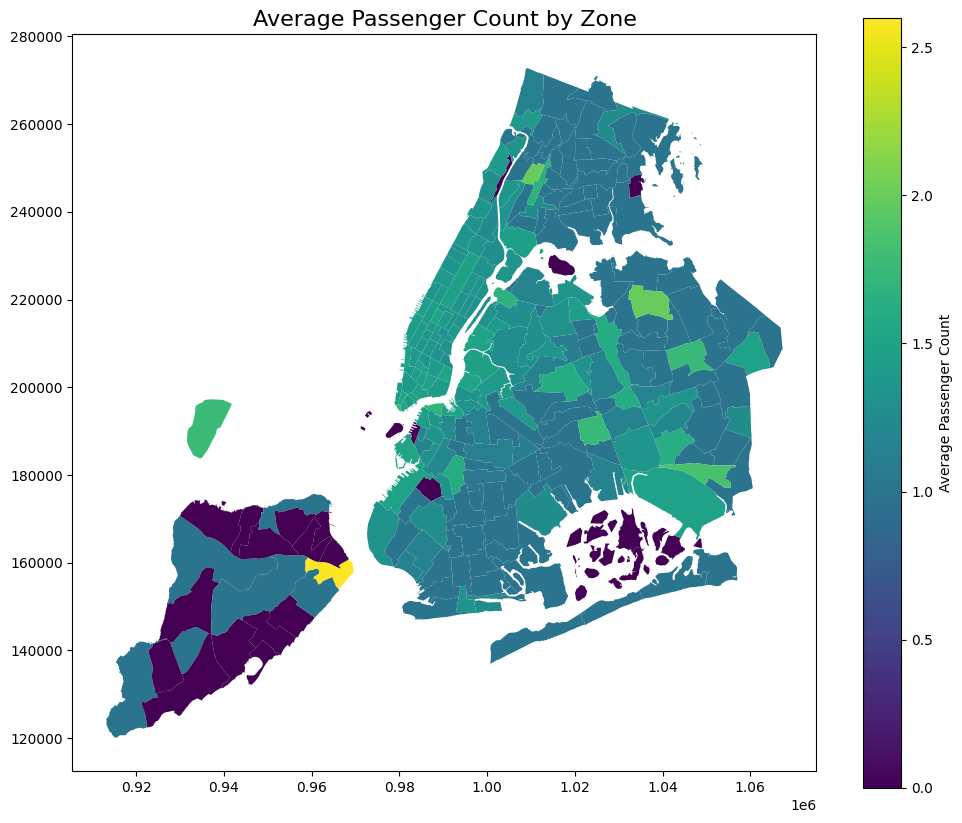

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
zones_with_passenger_counts.plot(
    column="avg_passenger_count",
    cmap="viridis",
    legend=True,
    legend_kwds={"label": "Average Passenger Count"},
    ax=ax,
)
plt.title("Average Passenger Count by Zone", fontsize=16)
plt.show()

Groups are largest at night and at weekends (about 1.45–1.46 passengers per trip between 1 am and 3 am; about 1.46–1.48 on Saturday and Sunday versus about 1.33–1.36 from Monday to Thursday). The zones with the highest averages (Arrochar/Fort Wadsworth, Murray Hill-Queens, Mount Hope, Springfield Gardens South, Newark Airport) are mostly outer-borough zones that probably see few trips, so their averages are noisy.

**Surcharges.** How often each extra charge is applied, then where and when.

In [ ]:
surcharge_columns = ["extra", "mta_tax", "congestion_surcharge", "tolls_amount"]
surcharge_freq = merged_data[surcharge_columns].gt(0).mean() * 100
print("Percentage of trips with surcharges:")
surcharge_freq

Percentage of trips with surcharges:


extra                   62.018604
mta_tax                 99.360688
congestion_surcharge    92.860847
tolls_amount             8.031796
dtype: float64

In [ ]:
MIN_TRIPS = 100  # ignore zones with fewer sampled trips: shares are unreliable at tiny volumes

# Share of each zone's trips on which each charge applies (a charge is "applied" when it is above zero)
surcharge_share_by_zone = (
    merged_data[surcharge_columns].gt(0).groupby(merged_data["PULocationID"]).mean() * 100
)

surcharge_by_zone = zones_with_trips.merge(
    surcharge_share_by_zone, how="left", left_on="LocationID", right_index=True
)

busy_zones = surcharge_by_zone[surcharge_by_zone["total_trips"] >= MIN_TRIPS]

print(f"Zones where the congestion surcharge is applied most often (zones with at least {MIN_TRIPS} sampled trips):")
busy_zones[["zone", "borough", "total_trips", *surcharge_columns]].sort_values(
    "congestion_surcharge", ascending=False
).head(10).reset_index(drop=True)

In [ ]:
merged_data["pickup_hour"] = merged_data["tpep_pickup_datetime"].dt.hour

# Share of trips (%) on which each charge applies, by pickup hour
surcharge_share_by_hour = (
    merged_data[surcharge_columns].gt(0).groupby(merged_data["pickup_hour"]).mean() * 100
)
print("Share of trips with each charge, by pickup hour (%):")
print(surcharge_share_by_hour.round(1))

In [ ]:
surcharge_share_by_hour.plot(kind="bar", figsize=(12, 6), colormap="viridis")
plt.title("Share of Trips with Each Surcharge, by Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Share of Trips (%)")
plt.legend(title="Charge", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## 4. Conclusions and recommendations

**What the data says.** Demand is strongly time-structured: a weekday evening peak at 6 pm, a smaller morning rise from 6 am, a very quiet 3–5 am, and a seasonal low from July to September. JFK Airport, the Upper East Side and Midtown are the highest-volume pickup zones. Fares follow distance, short trips earn the most per mile, and night hours bring in only about 12% of revenue.

### 4.1 Routing and dispatching

- Keep more cabs available in the highest-volume zones (JFK Airport, the Upper East Side, Midtown) and increase dispatch frequency around the weekday evening peak (the five busiest hours are 15 to 19).
- Zone 70 has the highest pickup-to-drop-off ratio (about 7.3 pickups per drop-off): cabs pick up there but rarely end trips there, so empty cabs should be routed in.
- Use route-speed analysis to steer drivers away from slow corridors, which should improve trip times and tips. Treat this as indicative, given the duration limitation noted in the README.
- Fewer cabs are needed from about 3 am to 5 am, when pickups are lowest (roughly 1,500 sampled pickups per hour versus about 21,500 at 6 pm).
- Reduce supply in weak zones from July to September, when pickups and revenue dip.

### 4.2 Positioning cabs

- Position cabs near the airports and the busiest zones ahead of the evening peak.
- Redirect empty cabs away from zones with no demand (for example Jamaica Bay, which recorded no pickups in the sample) towards busier zones or the airports.
- Shorter trips earn more per mile, so position cabs at common drop-off points as well, such as zones 236 and 237 on the Upper East Side.
- Maximise availability at the peak hour (18:00) across all active zones.

### 4.3 Pricing

- Introduce surge or peak pricing for the weekday evening peak and for airport trips.
- Offer pre-booking discounts to lock in demand ahead of peaks, and priority booking at a premium.
- Night hours are a small share of revenue (about 12%), so a flat-rate night fare or a night pass could stimulate demand without risking much revenue.
- Apply higher minimum fares at airport pickups and drop-offs while keeping per-mile rates competitive.
- Lower base fares in persistently low-demand zones to stimulate demand.